In [242]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import mean_squared_error, mean_absolute_error
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu126
CUDA available: True
Device: cuda
GPU: Quadro T1000


In [243]:

train_path = "../data/processed/train.csv"
test_path = "../data/processed/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)



In [244]:
# 2. Kiểm tra cấu trúc dữ liệu
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows of train:")
display(train_df.head())

print("\nFirst 5 rows of test:")
display(test_df.head())


Train shape: (88799, 6)
Test shape: (16342, 6)

Train columns:
['reviewers', 'course_id', 'rating', 'date_reviews', 'user_id', 'course_idx']

First 5 rows of train:


,reviewers,course_id,rating,date_reviews,user_id,course_idx
0,By George W,philosophy,5,2015-08-07,2736,384
1,By Konstantinos K,learning-how-to-learn,5,2015-08-07,4049,314
2,By Mohammed R,machine-learning,5,2015-08-07,5116,318
3,By Michelle F,learning-how-to-learn,5,2015-08-07,4948,314
4,By Tushar T,machine-learning,5,2015-08-07,7579,318



First 5 rows of test:


,reviewers,course_id,rating,date_reviews,user_id,course_idx
0,By Manojkumar P,wharton-customer-analytics,4,2015-12-29,4472,542
1,By Julien H J,wharton-customer-analytics,5,2016-01-13,3783,542
2,By Jingxia P,wharton-operations-analytics,3,2016-01-14,3486,551
3,By Roussel K,python,5,2016-01-14,6470,420
4,By Manojkumar P,terrorism,4,2016-01-16,4472,501


In [245]:
print("Missing values in train:")
print(train_df[["user_id", "course_idx", "rating"]].isnull().sum())

Missing values in train:
user_id       0
course_idx    0
rating        0
dtype: int64


In [246]:
n_users = train_df["user_id"].nunique()
n_items = train_df["course_idx"].nunique()

print("Number of users:", n_users)
print("Number of courses:", n_items)

Number of users: 8220
Number of courses: 564


In [247]:
print("user_id range:")
print(train_df["user_id"].min(), "->", train_df["user_id"].max())

print("\ncourse_idx range:")
print(train_df["course_idx"].min(), "->", train_df["course_idx"].max())

user_id range:
0 -> 8219

course_idx range:
0 -> 563


In [248]:
unseen_users = set(test_df["user_id"]) - set(train_df["user_id"])
unseen_items = set(test_df["course_idx"]) - set(train_df["course_idx"])

print("Users in test but not in train:", len(unseen_users))
print("Courses in test but not in train:", len(unseen_items))

Users in test but not in train: 0
Courses in test but not in train: 0


In [249]:
print(train_df["rating"].value_counts().sort_index())

rating
1     1433
2     1544
3     3853
4    15069
5    66900
Name: count, dtype: int64


In [250]:
total_possible = n_users * n_items
observed_ratings = len(train_df)

sparsity = 1 - observed_ratings / total_possible

print("Total possible user-course pairs:", total_possible)
print("Observed ratings:", observed_ratings)
print(f"Matrix sparsity: {sparsity:.4%}")
print(f"Matrix density: {1 - sparsity:.4%}")

Total possible user-course pairs: 4636080
Observed ratings: 88799
Matrix sparsity: 98.0846%
Matrix density: 1.9154%


In [251]:
data_summary = pd.DataFrame({
    "Metric": [
        "Number of users",
        "Number of courses",
        "Training ratings",
        "Testing ratings",
        "Rating levels",
        "Matrix sparsity"
    ],
    "Value": [
        n_users,
        n_items,
        len(train_df),
        len(test_df),
        train_df["rating"].nunique(),
        f"{sparsity:.4%}"
    ]
})

display(data_summary)

,Metric,Value
0,Number of users,8220
1,Number of courses,564
2,Training ratings,88799
3,Testing ratings,16342
4,Rating levels,5
5,Matrix sparsity,98.0846%


In [252]:
print("Train data types:")
print(train_df[["user_id", "course_idx", "rating"]].dtypes)

print("\nTest data types:")
print(test_df[["user_id", "course_idx", "rating"]].dtypes)

Train data types:
user_id       int64
course_idx    int64
rating        int64
dtype: object

Test data types:
user_id       int64
course_idx    int64
rating        int64
dtype: object


In [253]:
train_users = torch.tensor(
    train_df["user_id"].to_numpy(),
    dtype=torch.long,
    device=device
)

train_items = torch.tensor(
    train_df["course_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

train_ratings = torch.tensor(
    train_df["rating"].to_numpy(),
    dtype=torch.float32,
    device=device
)

print("train_users shape:", train_users.shape)
print("train_items shape:", train_items.shape)
print("train_ratings shape:", train_ratings.shape)

train_users shape: torch.Size([88799])
train_items shape: torch.Size([88799])
train_ratings shape: torch.Size([88799])


In [254]:
test_users = torch.tensor(
    test_df["user_id"].to_numpy(),
    dtype=torch.long,
    device=device
)

test_items = torch.tensor(
    test_df["course_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

test_ratings = torch.tensor(
    test_df["rating"].to_numpy(),
    dtype=torch.float32,
    device=device
)

print("test_users shape:", test_users.shape)
print("test_items shape:", test_items.shape)
print("test_ratings shape:", test_ratings.shape)

test_users shape: torch.Size([16342])
test_items shape: torch.Size([16342])
test_ratings shape: torch.Size([16342])


In [255]:
embedding_dim = 20

print("Number of users:", n_users)
print("Number of courses:", n_items)
print("Latent dimension (k):", embedding_dim)

Number of users: 8220
Number of courses: 564
Latent dimension (k): 20


In [256]:
user_embedding = nn.Embedding(n_users, embedding_dim)
item_embedding = nn.Embedding(n_items, embedding_dim)

print("User embedding shape:", user_embedding.weight.shape)
print("Item embedding shape:", item_embedding.weight.shape)

User embedding shape: torch.Size([8220, 20])
Item embedding shape: torch.Size([564, 20])


In [257]:
class MatrixFactorization(nn.Module):
    def __init__(self, n_users, n_items, embedding_dim):
        super().__init__()

        self.user_embedding = nn.Embedding(
            n_users, embedding_dim
        )
        self.item_embedding = nn.Embedding(
            n_items, embedding_dim
        )

        # Khởi tạo vector với giá trị nhỏ
        nn.init.normal_(self.user_embedding.weight, std=0.1)
        nn.init.normal_(self.item_embedding.weight, std=0.1)

    def forward(self, users, items):
        user_vectors = self.user_embedding(users)
        item_vectors = self.item_embedding(items)

        predictions = (user_vectors * item_vectors).sum(dim=1)

        return predictions

In [258]:
model = MatrixFactorization(
    n_users=n_users,
    n_items=n_items,
    embedding_dim=embedding_dim
).to(device)

print(model)

MatrixFactorization(
  (user_embedding): Embedding(8220, 20)
  (item_embedding): Embedding(564, 20)
)


In [259]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 175680


In [260]:
criterion = nn.MSELoss()

print("Loss function:", criterion)

Loss function: MSELoss()


In [261]:
lambda_reg = 0.01

print("L2 regularization coefficient:", lambda_reg)

L2 regularization coefficient: 0.01


In [262]:
learning_rate = 0.005

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)

Optimizer: Adam
Learning rate: 0.005


In [263]:
user_optimizer = torch.optim.Adam(
    model.user_embedding.parameters(),
    lr=learning_rate
)

item_optimizer = torch.optim.Adam(
    model.item_embedding.parameters(),
    lr=learning_rate
)

print("User optimizer:", user_optimizer.__class__.__name__)
print("Item optimizer:", item_optimizer.__class__.__name__)

User optimizer: Adam
Item optimizer: Adam


In [264]:
with torch.no_grad():
    sample_predictions = model(
        train_users[:5],
        train_items[:5]
    )

print("Actual ratings:", train_ratings[:5].cpu().numpy())
print("Predicted ratings:", sample_predictions.cpu().numpy())
print("Prediction shape:", sample_predictions.shape)

Actual ratings: [5. 5. 5. 5. 5.]
Predicted ratings: [ 0.08038464 -0.00331056  0.09838983  0.06515878 -0.07528462]
Prediction shape: torch.Size([5])


In [265]:
def calculate_loss(predictions, targets, user_vectors, item_vectors, lambda_reg):
    mse_loss = torch.mean((predictions - targets) ** 2)

    reg_loss = lambda_reg * (
        user_vectors.pow(2).sum()
        + item_vectors.pow(2).sum()
    ) / len(targets)

    total_loss = mse_loss + reg_loss

    return total_loss, mse_loss, reg_loss

In [266]:
with torch.no_grad():
    sample_users = train_users[:5]
    sample_items = train_items[:5]
    sample_ratings = train_ratings[:5]

    sample_predictions = model(sample_users, sample_items)

    sample_user_vectors = model.user_embedding(sample_users)
    sample_item_vectors = model.item_embedding(sample_items)

    total_loss, mse_loss, reg_loss = calculate_loss(
        predictions=sample_predictions,
        targets=sample_ratings,
        user_vectors=sample_user_vectors,
        item_vectors=sample_item_vectors,
        lambda_reg=lambda_reg
    )

print(f"MSE loss: {mse_loss.item():.6f}")
print(f"L2 regularization loss: {reg_loss.item():.6f}")
print(f"Total loss: {total_loss.item():.6f}")

MSE loss: 24.674536
L2 regularization loss: 0.004608
Total loss: 24.679144


In [267]:
def batch_loss(users, items, ratings, lambda_reg):
    predictions = model(users, items)

    user_vectors = model.user_embedding(users)
    item_vectors = model.item_embedding(items)

    total_loss, mse_loss, reg_loss = calculate_loss(
        predictions=predictions,
        targets=ratings,
        user_vectors=user_vectors,
        item_vectors=item_vectors,
        lambda_reg=lambda_reg
    )

    return total_loss, mse_loss, reg_loss

In [268]:
print("User embedding requires_grad:",
      model.user_embedding.weight.requires_grad)

print("Item embedding requires_grad:",
      model.item_embedding.weight.requires_grad)

User embedding requires_grad: True
Item embedding requires_grad: True


In [269]:
def set_trainable(user_trainable, item_trainable):
    model.user_embedding.weight.requires_grad_(user_trainable)
    model.item_embedding.weight.requires_grad_(item_trainable)

In [270]:
set_trainable(user_trainable=True, item_trainable=False)

print(
    "User embedding requires_grad:",
    model.user_embedding.weight.requires_grad
)

print(
    "Item embedding requires_grad:",
    model.item_embedding.weight.requires_grad
)

User embedding requires_grad: True
Item embedding requires_grad: False


In [271]:
set_trainable(user_trainable=False, item_trainable=True)

print(
    "User embedding requires_grad:",
    model.user_embedding.weight.requires_grad
)

print(
    "Item embedding requires_grad:",
    model.item_embedding.weight.requires_grad
)

User embedding requires_grad: False
Item embedding requires_grad: True


In [272]:
# Chỉ cập nhật user embedding
set_trainable(user_trainable=True, item_trainable=False)

user_optimizer.zero_grad()

loss, mse_loss, reg_loss = batch_loss(
    train_users[:5],
    train_items[:5],
    train_ratings[:5],
    lambda_reg
)

loss.backward()
user_optimizer.step()

print(f"Total loss before update: {loss.item():.6f}")
print(f"MSE loss: {mse_loss.item():.6f}")
print(f"L2 loss: {reg_loss.item():.6f}")

Total loss before update: 24.679144
MSE loss: 24.674536
L2 loss: 0.004608


In [273]:
# Lưu lại item embedding hiện tại
item_weights_before = model.item_embedding.weight.detach().clone()

# Chỉ cập nhật user embedding
set_trainable(user_trainable=True, item_trainable=False)
user_optimizer.zero_grad()

loss, _, _ = batch_loss(
    train_users[:5],
    train_items[:5],
    train_ratings[:5],
    lambda_reg
)

loss.backward()
user_optimizer.step()

# So sánh item embedding trước và sau cập nhật
item_weights_after = model.item_embedding.weight.detach()

max_item_change = (
    item_weights_after - item_weights_before
).abs().max().item()

print(f"Maximum item embedding change: {max_item_change:.10f}")

Maximum item embedding change: 0.0000000000


In [274]:
# Lưu lại user embedding hiện tại
user_weights_before = model.user_embedding.weight.detach().clone()

# Chỉ cập nhật item embedding
set_trainable(user_trainable=False, item_trainable=True)
item_optimizer.zero_grad()

loss, _, _ = batch_loss(
    train_users[:5],
    train_items[:5],
    train_ratings[:5],
    lambda_reg
)

loss.backward()
item_optimizer.step()

# So sánh user embedding trước và sau cập nhật
user_weights_after = model.user_embedding.weight.detach()

max_user_change = (
    user_weights_after - user_weights_before
).abs().max().item()

print(f"Maximum user embedding change: {max_user_change:.10f}")

Maximum user embedding change: 0.0000000000


In [275]:
# Đặt lại seed để kết quả có thể tái lập
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Khởi tạo mô hình mới
model = MatrixFactorization(
    n_users=n_users,
    n_items=n_items,
    embedding_dim=embedding_dim
).to(device)

# Tạo lại hai optimizer
user_optimizer = torch.optim.Adam(
    model.user_embedding.parameters(),
    lr=learning_rate
)

item_optimizer = torch.optim.Adam(
    model.item_embedding.parameters(),
    lr=learning_rate
)

# Cho phép tính gradient ở cả hai nhóm trước khi bắt đầu
set_trainable(user_trainable=True, item_trainable=True)

print("Model reinitialized successfully.")
print("Embedding dimension:", embedding_dim)
print("Device:", device)

Model reinitialized successfully.
Embedding dimension: 20
Device: cuda


In [276]:
from sklearn.model_selection import train_test_split

train_part_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

train_part_df = train_part_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training subset:", train_part_df.shape)
print("Validation set:", val_df.shape)
print("Test set (kept untouched):", test_df.shape)

Training subset: (71039, 6)
Validation set: (17760, 6)
Test set (kept untouched): (16342, 6)


In [277]:
train_part_users = torch.tensor(
    train_part_df["user_id"].to_numpy(),
    dtype=torch.long,
    device=device
)

train_part_items = torch.tensor(
    train_part_df["course_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

train_part_ratings = torch.tensor(
    train_part_df["rating"].to_numpy(),
    dtype=torch.float32,
    device=device
)

print("Train users:", train_part_users.shape)
print("Train items:", train_part_items.shape)
print("Train ratings:", train_part_ratings.shape)

Train users: torch.Size([71039])
Train items: torch.Size([71039])
Train ratings: torch.Size([71039])


In [278]:
val_users = torch.tensor(
    val_df["user_id"].to_numpy(),
    dtype=torch.long,
    device=device
)

val_items = torch.tensor(
    val_df["course_idx"].to_numpy(),
    dtype=torch.long,
    device=device
)

val_ratings = torch.tensor(
    val_df["rating"].to_numpy(),
    dtype=torch.float32,
    device=device
)

print("Validation users:", val_users.shape)
print("Validation items:", val_items.shape)
print("Validation ratings:", val_ratings.shape)

Validation users: torch.Size([17760])
Validation items: torch.Size([17760])
Validation ratings: torch.Size([17760])


In [279]:
def evaluate_model(model, users, items, ratings):
    model.eval()

    with torch.no_grad():
        predictions = model(users, items)

    predictions = predictions.cpu().numpy()
    actuals = ratings.cpu().numpy()

    rmse = np.sqrt(mean_squared_error(actuals, predictions))
    mae = mean_absolute_error(actuals, predictions)

    return rmse, mae

In [280]:
initial_rmse, initial_mae = evaluate_model(
    model,
    val_users,
    val_items,
    val_ratings
)

print(f"Initial Validation RMSE: {initial_rmse:.4f}")
print(f"Initial Validation MAE:  {initial_mae:.4f}")

Initial Validation RMSE: 4.6928
Initial Validation MAE:  4.6282


In [281]:
num_epochs = 20
batch_size = 1024
patience = 3

print("Number of epochs:", num_epochs)
print("Batch size:", batch_size)
print("Early stopping patience:", patience)

Number of epochs: 20
Batch size: 1024
Early stopping patience: 3


In [282]:
n_train = len(train_part_df)

n_batches = (n_train + batch_size - 1) // batch_size

print("Number of training samples:", n_train)
print("Batch size:", batch_size)
print("Number of batches per epoch:", n_batches)

Number of training samples: 71039
Batch size: 1024
Number of batches per epoch: 70


In [283]:
def train_one_batch(users, items, ratings, lambda_reg):
    # Giai đoạn 1: cập nhật user embedding
    set_trainable(user_trainable=True, item_trainable=False)
    user_optimizer.zero_grad()

    user_loss, _, _ = batch_loss(
        users, items, ratings, lambda_reg
    )
    user_loss.backward()
    user_optimizer.step()

    # Giai đoạn 2: cập nhật item embedding
    set_trainable(user_trainable=False, item_trainable=True)
    item_optimizer.zero_grad()

    item_loss, _, _ = batch_loss(
        users, items, ratings, lambda_reg
    )
    item_loss.backward()
    item_optimizer.step()

    # Khôi phục trạng thái để sẵn sàng cho bước tiếp theo
    set_trainable(user_trainable=True, item_trainable=True)

    return user_loss.item(), item_loss.item()

In [284]:
sample_size = 256

user_loss, item_loss = train_one_batch(
    train_part_users[:sample_size],
    train_part_items[:sample_size],
    train_part_ratings[:sample_size],
    lambda_reg
)

print(f"Loss after user update: {user_loss:.6f}")
print(f"Loss after item update: {item_loss:.6f}")

Loss after user update: 22.013863
Loss after item update: 21.939581


In [285]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = MatrixFactorization(
    n_users=n_users,
    n_items=n_items,
    embedding_dim=embedding_dim
).to(device)

user_optimizer = torch.optim.Adam(
    model.user_embedding.parameters(),
    lr=learning_rate
)

item_optimizer = torch.optim.Adam(
    model.item_embedding.parameters(),
    lr=learning_rate
)

set_trainable(user_trainable=True, item_trainable=True)

print("Model reset successfully.")
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Model reset successfully.
Trainable parameters: 175680


In [286]:
from copy import deepcopy

best_val_rmse = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0

history = []

for epoch in range(1, num_epochs + 1):
    model.train()

    # Xáo trộn thứ tự các mẫu mỗi epoch
    permutation = torch.randperm(n_train, device=device)

    epoch_user_loss = 0.0
    epoch_item_loss = 0.0
    num_batches_seen = 0

    for start in range(0, n_train, batch_size):
        batch_indices = permutation[start:start + batch_size]

        batch_users = train_part_users[batch_indices]
        batch_items = train_part_items[batch_indices]
        batch_ratings = train_part_ratings[batch_indices]

        user_loss, item_loss = train_one_batch(
            batch_users,
            batch_items,
            batch_ratings,
            lambda_reg
        )

        epoch_user_loss += user_loss
        epoch_item_loss += item_loss
        num_batches_seen += 1

    # Đánh giá trên validation
    val_rmse, val_mae = evaluate_model(
        model,
        val_users,
        val_items,
        val_ratings
    )

    avg_user_loss = epoch_user_loss / num_batches_seen
    avg_item_loss = epoch_item_loss / num_batches_seen

    history.append({
        "epoch": epoch,
        "user_loss": avg_user_loss,
        "item_loss": avg_item_loss,
        "val_rmse": val_rmse,
        "val_mae": val_mae
    })

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"User loss: {avg_user_loss:.4f} | "
        f"Item loss: {avg_item_loss:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"Val MAE: {val_mae:.4f}"
    )

    # Lưu mô hình tốt nhất theo validation RMSE
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch
        best_model_state = deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Khôi phục mô hình tốt nhất
if best_model_state is not None:
    model.load_state_dict(best_model_state)

set_trainable(user_trainable=True, item_trainable=True)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Best validation RMSE: {best_val_rmse:.4f}")

Epoch 01/20 | User loss: 22.0097 | Item loss: 21.9794 | Val RMSE: 4.6776 | Val MAE: 4.6128
Epoch 02/20 | User loss: 20.1134 | Item loss: 20.0195 | Val RMSE: 4.1545 | Val MAE: 4.0635
Epoch 03/20 | User loss: 10.2068 | Item loss: 10.0304 | Val RMSE: 2.3093 | Val MAE: 2.0114
Epoch 04/20 | User loss: 2.5808 | Item loss: 2.5160 | Val RMSE: 1.3211 | Val MAE: 1.0411
Epoch 05/20 | User loss: 1.0204 | Item loss: 0.9965 | Val RMSE: 0.9965 | Val MAE: 0.7618
Epoch 06/20 | User loss: 0.7128 | Item loss: 0.6973 | Val RMSE: 0.8948 | Val MAE: 0.6764
Epoch 07/20 | User loss: 0.6225 | Item loss: 0.6090 | Val RMSE: 0.8582 | Val MAE: 0.6439
Epoch 08/20 | User loss: 0.5754 | Item loss: 0.5628 | Val RMSE: 0.8443 | Val MAE: 0.6320
Epoch 09/20 | User loss: 0.5425 | Item loss: 0.5304 | Val RMSE: 0.8412 | Val MAE: 0.6275
Epoch 10/20 | User loss: 0.5134 | Item loss: 0.5018 | Val RMSE: 0.8406 | Val MAE: 0.6232
Epoch 11/20 | User loss: 0.4859 | Item loss: 0.4748 | Val RMSE: 0.8453 | Val MAE: 0.6270
Epoch 12/20 | U

In [287]:
history_df = pd.DataFrame(history)

display(history_df.round(4))

,epoch,user_loss,item_loss,val_rmse,val_mae
0,1,22.0097,21.9794,4.6776,4.6128
1,2,20.1134,20.0195,4.1545,4.0635
2,3,10.2068,10.0304,2.3093,2.0114
3,4,2.5808,2.5160,1.3211,1.0411
4,5,1.0204,0.9965,0.9965,0.7618
5,6,0.7128,0.6973,0.8948,0.6764
6,7,0.6225,0.6090,0.8582,0.6439
7,8,0.5754,0.5628,0.8443,0.6320
8,9,0.5425,0.5304,0.8412,0.6275
9,10,0.5134,0.5018,0.8406,0.6232


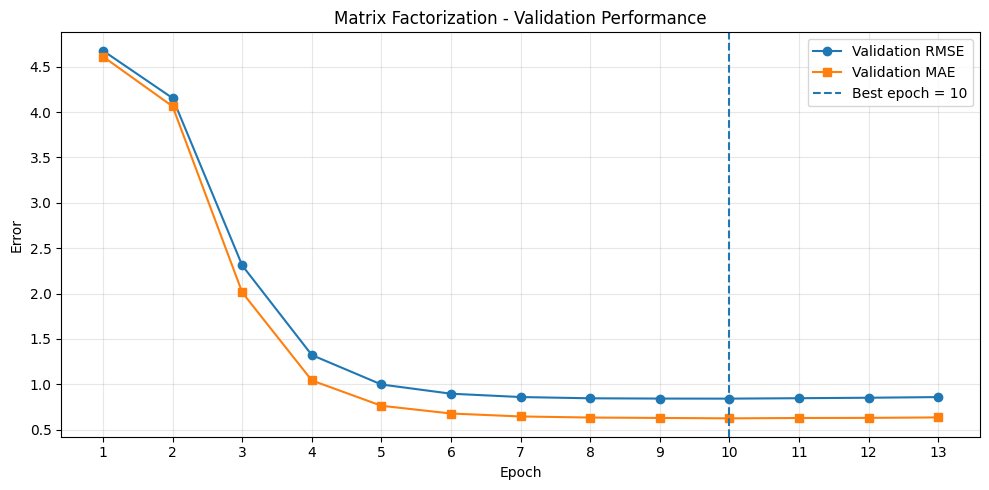

In [288]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["val_rmse"],
    marker="o",
    label="Validation RMSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_mae"],
    marker="s",
    label="Validation MAE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Error")
plt.title("Matrix Factorization - Validation Performance")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [289]:
test_rmse, test_mae = evaluate_model(
    model,
    test_users,
    test_items,
    test_ratings
)

print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test MAE:  {test_mae:.4f}")

Test RMSE: 0.8696
Test MAE:  0.6527


In [290]:
embedding_dims = [20, 50, 100]

print("Embedding dimensions to evaluate:", embedding_dims)

Embedding dimensions to evaluate: [20, 50, 100]


In [291]:
def train_mf_model(embedding_dim):
    # Khởi tạo mô hình mới
    model_k = MatrixFactorization(
        n_users=n_users,
        n_items=n_items,
        embedding_dim=embedding_dim
    ).to(device)

    user_opt = torch.optim.Adam(
        model_k.user_embedding.parameters(),
        lr=learning_rate
    )

    item_opt = torch.optim.Adam(
        model_k.item_embedding.parameters(),
        lr=learning_rate
    )

    best_rmse = float("inf")
    best_epoch_k = 0
    best_state = None
    patience_counter = 0
    history_k = []

    for epoch in range(1, num_epochs + 1):
        model_k.train()

        permutation = torch.randperm(n_train, device=device)
        epoch_user_loss = 0.0
        epoch_item_loss = 0.0
        batches_seen = 0

        for start in range(0, n_train, batch_size):
            indices = permutation[start:start + batch_size]

            batch_users = train_part_users[indices]
            batch_items = train_part_items[indices]
            batch_ratings = train_part_ratings[indices]

            # Giai đoạn 1: cập nhật user embedding
            model_k.user_embedding.weight.requires_grad_(True)
            model_k.item_embedding.weight.requires_grad_(False)
            user_opt.zero_grad()

            user_vectors = model_k.user_embedding(batch_users)
            item_vectors = model_k.item_embedding(batch_items)
            predictions = (user_vectors * item_vectors).sum(dim=1)

            user_loss = (
                (predictions - batch_ratings).pow(2).mean()
                + lambda_reg * (
                    user_vectors.pow(2).sum()
                    + item_vectors.pow(2).sum()
                ) / len(batch_ratings)
            )

            user_loss.backward()
            user_opt.step()

            # Giai đoạn 2: cập nhật item embedding
            model_k.user_embedding.weight.requires_grad_(False)
            model_k.item_embedding.weight.requires_grad_(True)
            item_opt.zero_grad()

            user_vectors = model_k.user_embedding(batch_users)
            item_vectors = model_k.item_embedding(batch_items)
            predictions = (user_vectors * item_vectors).sum(dim=1)

            item_loss = (
                (predictions - batch_ratings).pow(2).mean()
                + lambda_reg * (
                    user_vectors.pow(2).sum()
                    + item_vectors.pow(2).sum()
                ) / len(batch_ratings)
            )

            item_loss.backward()
            item_opt.step()

            epoch_user_loss += user_loss.item()
            epoch_item_loss += item_loss.item()
            batches_seen += 1

        # Đánh giá validation
        model_k.user_embedding.weight.requires_grad_(True)
        model_k.item_embedding.weight.requires_grad_(True)

        val_rmse_k, val_mae_k = evaluate_model(
            model_k, val_users, val_items, val_ratings
        )

        history_k.append({
            "epoch": epoch,
            "user_loss": epoch_user_loss / batches_seen,
            "item_loss": epoch_item_loss / batches_seen,
            "val_rmse": val_rmse_k,
            "val_mae": val_mae_k
        })

        print(
            f"k={embedding_dim} | Epoch {epoch:02d} | "
            f"Val RMSE: {val_rmse_k:.4f} | "
            f"Val MAE: {val_mae_k:.4f}"
        )

        if val_rmse_k < best_rmse:
            best_rmse = val_rmse_k
            best_epoch_k = epoch
            best_state = {
                name: value.detach().clone()
                for name, value in model_k.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping for k={embedding_dim} at epoch {epoch}.")
            break

    model_k.load_state_dict(best_state)

    return model_k, best_rmse, best_epoch_k, pd.DataFrame(history_k)

In [292]:
model_k20, rmse_k20, epoch_k20, history_k20 = train_mf_model(20)

print("\nResults for k=20")
print(f"Best epoch: {epoch_k20}")
print(f"Best validation RMSE: {rmse_k20:.4f}")

k=20 | Epoch 01 | Val RMSE: 4.6830 | Val MAE: 4.6183
k=20 | Epoch 02 | Val RMSE: 4.2521 | Val MAE: 4.1683
k=20 | Epoch 03 | Val RMSE: 2.4730 | Val MAE: 2.1874
k=20 | Epoch 04 | Val RMSE: 1.4013 | Val MAE: 1.1163
k=20 | Epoch 05 | Val RMSE: 1.0450 | Val MAE: 0.8055
k=20 | Epoch 06 | Val RMSE: 0.9266 | Val MAE: 0.7075
k=20 | Epoch 07 | Val RMSE: 0.8831 | Val MAE: 0.6705
k=20 | Epoch 08 | Val RMSE: 0.8664 | Val MAE: 0.6539
k=20 | Epoch 09 | Val RMSE: 0.8592 | Val MAE: 0.6472
k=20 | Epoch 10 | Val RMSE: 0.8608 | Val MAE: 0.6471
k=20 | Epoch 11 | Val RMSE: 0.8622 | Val MAE: 0.6451
k=20 | Epoch 12 | Val RMSE: 0.8687 | Val MAE: 0.6481
Early stopping for k=20 at epoch 12.

Results for k=20
Best epoch: 9
Best validation RMSE: 0.8592


In [293]:
model_k50, rmse_k50, epoch_k50, history_k50 = train_mf_model(50)

print("\nResults for k=50")
print(f"Best epoch: {epoch_k50}")
print(f"Best validation RMSE: {rmse_k50:.4f}")

k=50 | Epoch 01 | Val RMSE: 4.6583 | Val MAE: 4.5925
k=50 | Epoch 02 | Val RMSE: 3.6337 | Val MAE: 3.4827
k=50 | Epoch 03 | Val RMSE: 1.6785 | Val MAE: 1.3714
k=50 | Epoch 04 | Val RMSE: 1.1237 | Val MAE: 0.8957
k=50 | Epoch 05 | Val RMSE: 1.0023 | Val MAE: 0.8017
k=50 | Epoch 06 | Val RMSE: 0.9736 | Val MAE: 0.7778
k=50 | Epoch 07 | Val RMSE: 0.9660 | Val MAE: 0.7726
k=50 | Epoch 08 | Val RMSE: 0.9706 | Val MAE: 0.7751
k=50 | Epoch 09 | Val RMSE: 0.9743 | Val MAE: 0.7771
k=50 | Epoch 10 | Val RMSE: 0.9844 | Val MAE: 0.7850
Early stopping for k=50 at epoch 10.

Results for k=50
Best epoch: 7
Best validation RMSE: 0.9660


In [294]:
model_k100, rmse_k100, epoch_k100, history_k100 = train_mf_model(100)

print("\nResults for k=100")
print(f"Best epoch: {epoch_k100}")
print(f"Best validation RMSE: {rmse_k100:.4f}")

k=100 | Epoch 01 | Val RMSE: 4.6166 | Val MAE: 4.5490
k=100 | Epoch 02 | Val RMSE: 2.9166 | Val MAE: 2.6477
k=100 | Epoch 03 | Val RMSE: 1.4061 | Val MAE: 1.1423
k=100 | Epoch 04 | Val RMSE: 1.1644 | Val MAE: 0.9658
k=100 | Epoch 05 | Val RMSE: 1.1311 | Val MAE: 0.9437
k=100 | Epoch 06 | Val RMSE: 1.1275 | Val MAE: 0.9410
k=100 | Epoch 07 | Val RMSE: 1.1301 | Val MAE: 0.9430
k=100 | Epoch 08 | Val RMSE: 1.1390 | Val MAE: 0.9505
k=100 | Epoch 09 | Val RMSE: 1.1434 | Val MAE: 0.9538
Early stopping for k=100 at epoch 9.

Results for k=100
Best epoch: 6
Best validation RMSE: 1.1275


In [295]:
test_rmse_k20, test_mae_k20 = evaluate_model(
    model_k20,
    test_users,
    test_items,
    test_ratings
)

print("Best configuration: k=20")
print(f"Best epoch: {epoch_k20}")
print(f"Test RMSE: {test_rmse_k20:.4f}")
print(f"Test MAE:  {test_mae_k20:.4f}")

Best configuration: k=20
Best epoch: 9
Test RMSE: 0.9042
Test MAE:  0.6951


In [296]:
class BiasedMatrixFactorization(nn.Module):
    def __init__(self, n_users, n_items, embedding_dim, global_mean):
        super().__init__()

        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.item_embedding = nn.Embedding(n_items, embedding_dim)

        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)

        self.global_mean = global_mean

        nn.init.normal_(self.user_embedding.weight, std=0.05)
        nn.init.normal_(self.item_embedding.weight, std=0.05)

        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)

    def forward(self, users, items):
        user_vectors = self.user_embedding(users)
        item_vectors = self.item_embedding(items)

        interaction = (user_vectors * item_vectors).sum(dim=1)

        bu = self.user_bias(users).squeeze(-1)
        bi = self.item_bias(items).squeeze(-1)

        return self.global_mean + bu + bi + interaction

In [297]:
global_mean = float(train_part_df["rating"].mean())

model_bmf = BiasedMatrixFactorization(
    n_users=n_users,
    n_items=n_items,
    embedding_dim=20,
    global_mean=global_mean
).to(device)

optimizer_bmf = torch.optim.Adam(
    model_bmf.parameters(),
    lr=0.001
)

lambda_reg = 0.01

In [298]:
best_val_rmse = float("inf")
best_state = None
patience_counter = 0
patience = 3
num_epochs = 30

history_bmf = []

for epoch in range(1, num_epochs + 1):
    model_bmf.train()

    permutation = torch.randperm(n_train, device=device)
    total_loss = 0.0
    n_batches = 0

    for start in range(0, n_train, batch_size):
        indices = permutation[start:start + batch_size]

        users = train_part_users[indices]
        items = train_part_items[indices]
        ratings = train_part_ratings[indices]

        optimizer_bmf.zero_grad()

        predictions = model_bmf(users, items)

        mse = ((predictions - ratings) ** 2).mean()

        user_vecs = model_bmf.user_embedding(users)
        item_vecs = model_bmf.item_embedding(items)

        user_bias = model_bmf.user_bias(users)
        item_bias = model_bmf.item_bias(items)

        reg = lambda_reg * (
            user_vecs.pow(2).sum()
            + item_vecs.pow(2).sum()
            + user_bias.pow(2).sum()
            + item_bias.pow(2).sum()
        ) / len(ratings)

        loss = mse + reg

        loss.backward()
        optimizer_bmf.step()

        total_loss += loss.item()
        n_batches += 1

    val_rmse, val_mae = evaluate_model(
        model_bmf,
        val_users,
        val_items,
        val_ratings
    )

    history_bmf.append({
        "epoch": epoch,
        "train_loss": total_loss / n_batches,
        "val_rmse": val_rmse,
        "val_mae": val_mae
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Loss: {total_loss / n_batches:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"Val MAE: {val_mae:.4f}"
    )

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_state = {
            k: v.detach().clone()
            for k, v in model_bmf.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping.")
        break

model_bmf.load_state_dict(best_state)

Epoch 01 | Loss: 0.6179 | Val RMSE: 0.7665 | Val MAE: 0.5432
Epoch 02 | Loss: 0.5980 | Val RMSE: 0.7604 | Val MAE: 0.5321
Epoch 03 | Loss: 0.5806 | Val RMSE: 0.7558 | Val MAE: 0.5234
Epoch 04 | Loss: 0.5633 | Val RMSE: 0.7521 | Val MAE: 0.5166
Epoch 05 | Loss: 0.5440 | Val RMSE: 0.7494 | Val MAE: 0.5111
Epoch 06 | Loss: 0.5198 | Val RMSE: 0.7473 | Val MAE: 0.5068
Epoch 07 | Loss: 0.4939 | Val RMSE: 0.7460 | Val MAE: 0.5035
Epoch 08 | Loss: 0.4629 | Val RMSE: 0.7455 | Val MAE: 0.5016
Epoch 09 | Loss: 0.4336 | Val RMSE: 0.7460 | Val MAE: 0.5008
Epoch 10 | Loss: 0.4023 | Val RMSE: 0.7473 | Val MAE: 0.5013
Epoch 11 | Loss: 0.3724 | Val RMSE: 0.7495 | Val MAE: 0.5027
Early stopping.


<All keys matched successfully>

In [299]:
test_rmse_bmf, test_mae_bmf = evaluate_model(
    model_bmf,
    test_users,
    test_items,
    test_ratings
)

print(f"Biased MF Test RMSE: {test_rmse_bmf:.4f}")
print(f"Biased MF Test MAE:  {test_mae_bmf:.4f}")

Biased MF Test RMSE: 0.7563
Biased MF Test MAE:  0.4904


In [300]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Chỉ sử dụng tập huấn luyện con để tính baseline
global_mean_val = train_part_df["rating"].mean()

y_val = val_df["rating"].to_numpy()

# Baseline 1: Global Mean
pred_global_val = np.full(len(val_df), global_mean_val)

# Baseline 2: Item Average
item_means_val = train_part_df.groupby("course_idx")["rating"].mean()

pred_item_val = (
    val_df["course_idx"]
    .map(item_means_val)
    .fillna(global_mean_val)
    .to_numpy()
)

def print_metrics(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:20s} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

print_metrics("Global Mean", y_val, pred_global_val)
print_metrics("Item Average", y_val, pred_item_val)

Global Mean          | RMSE: 0.7747 | MAE: 0.5587
Item Average         | RMSE: 0.7452 | MAE: 0.5103


In [301]:
def train_biased_mf(lambda_reg, embedding_dim=20,
                    learning_rate=0.001, num_epochs=30,
                    patience=3):

    # Cố định seed để các cấu hình bắt đầu từ cùng điều kiện
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = BiasedMatrixFactorization(
        n_users=n_users,
        n_items=n_items,
        embedding_dim=embedding_dim,
        global_mean=float(train_part_df["rating"].mean())
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.0
    )

    best_rmse = float("inf")
    best_epoch = 0
    best_state = None
    wait = 0
    history = []

    model.global_mean = float(train_part_df["rating"].mean())

    for epoch in range(1, num_epochs + 1):
        model.train()
        permutation = torch.randperm(n_train, device=device)

        total_loss = 0.0
        n_batches = 0

        for start in range(0, n_train, batch_size):
            idx = permutation[start:start + batch_size]

            users = train_part_users[idx]
            items = train_part_items[idx]
            ratings = train_part_ratings[idx]

            optimizer.zero_grad()

            predictions = model(users, items)
            mse = ((predictions - ratings) ** 2).mean()

            user_vecs = model.user_embedding(users)
            item_vecs = model.item_embedding(items)
            user_bias = model.user_bias(users)
            item_bias = model.item_bias(items)

            # Giữ cùng cách tính regularization giữa các cấu hình
            reg = lambda_reg * (
                user_vecs.pow(2).sum()
                + item_vecs.pow(2).sum()
                + user_bias.pow(2).sum()
                + item_bias.pow(2).sum()
            ) / len(ratings)

            loss = mse + reg
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            n_batches += 1

        val_rmse, val_mae = evaluate_model(
            model, val_users, val_items, val_ratings
        )

        history.append({
            "epoch": epoch,
            "train_loss": total_loss / n_batches,
            "val_rmse": val_rmse,
            "val_mae": val_mae
        })

        if val_rmse < best_rmse:
            best_rmse = val_rmse
            best_epoch = epoch
            best_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)

    return model, best_rmse, best_epoch, pd.DataFrame(history)


# Thử nghiệm B1: so sánh regularization
results = {}
histories = {}

for reg_value in [0.01, 0.03, 0.05]:
    model, best_rmse, best_epoch, history = train_biased_mf(
        lambda_reg=reg_value
    )

    results[reg_value] = {
        "model": model,
        "val_rmse": best_rmse,
        "best_epoch": best_epoch
    }
    histories[reg_value] = history

    print(
        f"lambda={reg_value:.3f} | "
        f"Best epoch={best_epoch} | "
        f"Val RMSE={best_rmse:.4f} | "
        f"Val MAE={history.loc[history['val_rmse'].idxmin(), 'val_mae']:.4f}"
    )

lambda=0.010 | Best epoch=8 | Val RMSE=0.7449 | Val MAE=0.5023
lambda=0.030 | Best epoch=10 | Val RMSE=0.7426 | Val MAE=0.4976
lambda=0.050 | Best epoch=11 | Val RMSE=0.7404 | Val MAE=0.4950


In [302]:
best_lambda = min(
    results,
    key=lambda x: results[x]["val_rmse"]
)

best_model = results[best_lambda]["model"]

print("Best lambda:", best_lambda)
print("Best epoch:", results[best_lambda]["best_epoch"])
print("Best validation RMSE:", results[best_lambda]["val_rmse"])

comparison = pd.DataFrame([
    {
        "Model": "Global Mean",
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_global_val)),
        "MAE": mean_absolute_error(y_val, pred_global_val)
    },
    {
        "Model": "Item Average",
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_item_val)),
        "MAE": mean_absolute_error(y_val, pred_item_val)
    },
    *[
        {
            "Model": f"Biased MF (lambda={reg})",
            "RMSE": results[reg]["val_rmse"],
            "MAE": histories[reg].loc[
                histories[reg]["val_rmse"].idxmin(), "val_mae"
            ]
        }
        for reg in results
    ]
])

display(comparison.sort_values("RMSE").reset_index(drop=True))

Best lambda: 0.05
Best epoch: 11
Best validation RMSE: 0.7404479672312018


,Model,RMSE,MAE
0,Biased MF (lambda=0.05),0.740448,0.494978
1,Biased MF (lambda=0.03),0.742554,0.497631
2,Biased MF (lambda=0.01),0.744935,0.502276
3,Item Average,0.745250,0.510312
4,Global Mean,0.774665,0.558680


In [303]:
test_rmse, test_mae = evaluate_model(
    best_model,
    test_users,
    test_items,
    test_ratings
)

print(f"Selected lambda: {best_lambda}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test MAE:  {test_mae:.4f}")

Selected lambda: 0.05
Test RMSE: 0.7513
Test MAE:  0.4831
